# Chapter 13 — Deploying scikit-learn Models in Production

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Melatih model hanyalah separuh pekerjaan. Sebuah model baru memberi nilai ketika ia **di-*deploy***: dipindahkan dari lingkungan pengembangan (notebook, laptop) ke lingkungan produksi sehingga pengguna atau sistem lain dapat meminta prediksi darinya. *Deployment* mencakup beberapa hal sekaligus: menyiapkan **artefak** model yang andal (beserta metadatanya), **menyajikan** (*serving*) model dengan latensi dan *throughput* yang memadai, **memantau** apakah kinerjanya tetap baik ketika data berubah, serta **mengotomatiskan** seluruh siklus itu lewat *pipeline* CI/CD/CT (*Continuous Integration / Continuous Delivery / Continuous Training*). Chapter ini membahas langkah-langkah tersebut secara praktis dengan scikit-learn, `joblib`, dan beberapa pustaka pendukung.

**Daftar Isi**

1. 13.1 Pengantar Deployment Model (persistensi dasar + menyajikan model lewat REST API)
2. 13.2 Teknik Serialisasi dan Persistensi (`pickle`, `joblib`, `skops`, ONNX)
3. 13.3 Scaling Model untuk Produksi (`n_jobs`, *batch serving*)
4. 13.4 Monitoring dan Memperbarui Model yang Sudah Di-deploy (*drift*, `partial_fit`)
5. 13.5 Mengelola Siklus Hidup Model (versioning, metadata, reproduksibilitas)
6. 13.6 Menyiapkan Deployment Pipeline (validasi otomatis / *quality gate*)
7. Latihan (Exercise 1–3)
8. Ringkasan Chapter 13

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 13 (urutan resep sama dengan notebook resmi Packt, termasuk solusi latihan), dengan penyesuaian agar berjalan di scikit-learn 1.9 dan agar **aman dijalankan di notebook**:
> - Semua artefak (`.joblib`, `.pkl`, `.json`, dll.) ditulis ke **direktori sementara** (`tempfile`), bukan ke folder repositori, dan dihapus di akhir notebook.
> - Contoh REST API (Flask dan FastAPI) **tidak menjalankan server sungguhan**; permintaan HTTP disimulasikan *in-process* dengan `app.test_client()` (Flask) dan `TestClient` (FastAPI). Hal-hal yang tidak bisa dijalankan di notebook (Dockerfile, perintah `docker`, konfigurasi CI) ditampilkan sebagai blok kode Markdown beserta penjelasannya.
> - Seed acak ditambahkan pada data yang di-*generate* dengan `np.random` agar hasil dapat direproduksi.

## Import Library

In [1]:
%matplotlib inline
import warnings
import os, sys, json, time, pickle, hashlib, shutil, tempfile, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from joblib import dump, load

from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from IPython.display import display

warnings.filterwarnings('ignore', message='.*httpx.*')   # peringatan deprecation dari starlette.testclient

plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

# Semua artefak model disimpan di direktori sementara, BUKAN di dalam repositori
ART_DIR = Path(tempfile.mkdtemp(prefix='ch13_artifacts_'))
print('Direktori artefak :', ART_DIR)
print('python       :', platform.python_version())
print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)
print('joblib       :', joblib.__version__)

Direktori artefak : C:\Users\ahmad\AppData\Local\Temp\ch13_artifacts_qdzy9_80
python       : 3.12.15
numpy        : 2.5.4
pandas       : 3.1.0
scikit-learn : 1.9.1
joblib       : 1.6.0


## 13.1 Pengantar Deployment Model

**Teori:**

**Apa itu *deployment*?** Dalam siklus hidup *machine learning*, ada dua fase yang sangat berbeda sifatnya:

| Fase | Frekuensi | Tujuan | Lingkungan |
|---|---|---|---|
| **Training** (`fit`) | jarang (sekali per siklus CI/CD/CT) | mengestimasi parameter $\hat\theta$ dari data historis | notebook / *cluster* training |
| **Inference** (`predict`) | terus-menerus, ribuan–jutaan kali | menghitung $\hat y = f(x;\hat\theta)$ untuk input baru | server produksi, *batch job*, perangkat *edge* |

Karena kedua fase terpisah (waktu, mesin, bahkan tim), parameter hasil training harus **dipersistensikan** (*persist*) — disimpan ke berkas sebagai **artefak model** — lalu dimuat ulang di lingkungan produksi. Prinsip pentingnya: objek yang dimuat harus berperilaku **identik** dengan objek aslinya, yaitu $f_{\text{loaded}}(x) = f_{\text{original}}(x)$ untuk setiap $x$.

**Pola penyajian (*serving patterns*).**

1. **Batch / offline scoring** — model dijalankan terjadwal (mis. tiap malam) atas tabel besar; hasil disimpan ke basis data. Latensi tidak kritis, *throughput* penting.
2. **Online / real-time serving** — model dibungkus sebagai **REST API** (Flask, FastAPI) atau gRPC; klien mengirim fitur dalam JSON lewat HTTP `POST` dan menerima prediksi. Latensi per permintaan (mis. < 100 ms) menjadi kritis.
3. **Streaming** — model membaca *event* dari antrean (Kafka, Kinesis) dan memprediksi per *event*.
4. **Embedded / edge** — model diekspor ke format netral (ONNX) agar dapat dijalankan tanpa Python (C++, mobile, browser).

**Kontrak API.** Pada *online serving*, model diperlakukan sebagai fungsi di balik *endpoint*, misalnya `POST /predict` dengan *body* `{"features": [[x11, ..., x1p], ...]}` dan respons `{"predictions": [...], "probabilities": [...]}`. Kontrak ini harus memvalidasi **skema input** (jumlah fitur, tipe numerik) — model scikit-learn akan gagal (atau lebih buruk: memberi prediksi keliru tanpa *error*) bila urutan atau jumlah fitur tidak sesuai dengan saat training. Framework seperti **FastAPI** memakai *Pydantic* untuk validasi skema otomatis (respons HTTP 422 bila input tidak valid).

**Kontainerisasi.** Agar lingkungan produksi identik dengan lingkungan training (versi Python, NumPy, scikit-learn), aplikasi API biasanya dikemas dalam **Docker image**. Hal ini penting karena artefak `joblib`/`pickle` **tidak dijamin kompatibel** antar-versi scikit-learn.

**Pitfall umum:** (1) memuat model di *setiap* permintaan (lambat — model harus dimuat sekali saat aplikasi start); (2) preprocessing di produksi berbeda dari training (*training–serving skew*) — solusinya: simpan seluruh `Pipeline`; (3) tidak memvalidasi input; (4) versi pustaka berbeda antara training dan serving.

Kode buku: melatih `LogisticRegression` sederhana, menyimpannya dengan `joblib`, lalu memuat ulang dan memprediksi satu sampel baru (seolah-olah di lingkungan produksi).

In [2]:
# Membuat dan melatih model sederhana
X, y = make_classification(n_samples=1000, n_features=20, random_state=2024)
clf = LogisticRegression()
clf.fit(X, y)

# Simpan model terlatih dengan joblib (ke direktori sementara)
model_path = ART_DIR / 'model.joblib'
dump(clf, model_path)

# Muat kembali model (simulasi lingkungan baru)
clf_loaded = load(model_path)

# Prediksi dengan model hasil muat ulang
np.random.seed(2024)
incoming = np.random.rand(1, 20)
print('Prediksi model yang dimuat :', clf_loaded.predict(incoming))
print('Probabilitas kelas         :', clf_loaded.predict_proba(incoming).round(4))
print('Ukuran berkas              :', model_path.stat().st_size, 'byte')

# Verifikasi: model asli dan hasil muat identik pada seluruh data
print('Prediksi identik di seluruh X :', np.array_equal(clf.predict(X), clf_loaded.predict(X)))
print('Koefisien identik             :', np.array_equal(clf.coef_, clf_loaded.coef_))

Prediksi model yang dimuat : [1]
Probabilitas kelas         : [[0.1549 0.8451]]
Ukuran berkas              : 1007 byte
Prediksi identik di seluruh X : True
Koefisien identik             : True


**Interpretasi:**


- Model yang dimuat ulang dari `model.joblib` memprediksi kelas **1** untuk sampel acak `incoming` dengan probabilitas $P(y=1)\approx$ **0.845**. Sampel ini diambil dari distribusi seragam $[0,1]^{20}$, berbeda dari distribusi data training, sehingga prediksi ini hanya demonstrasi alur, bukan prediksi yang bermakna.
- Verifikasi *round-trip* memberi `True` untuk prediksi di seluruh 1000 baris **dan** untuk koefisien: model hasil muat ulang identik bit-per-bit dengan model asli.
- Artefak hanya berukuran sekitar **1 KB** (1007 byte), karena regresi logistik dengan 20 fitur hanya menyimpan 20 koefisien + 1 intersep, ditambah sedikit metadata objek.

### Menyajikan model sebagai REST API (Flask) — disimulasikan *in-process*

Buku menjelaskan bahwa artefak `.joblib` diunggah ke server produksi dan dimuat oleh aplikasi yang melayani prediksi. Di bawah ini aplikasi **Flask** minimal: model dimuat **sekali** saat aplikasi dibuat, ada *endpoint* `GET /health` (untuk *health check* dari *load balancer* / Kubernetes) dan `POST /predict`. Alih-alih menjalankan `app.run()` (yang akan memblokir notebook), kita memakai `app.test_client()` yang mengirim permintaan HTTP secara *in-process*.

In [3]:
from flask import Flask, request, jsonify

def create_flask_app(model_path):
    app = Flask(__name__)
    model = load(model_path)              # dimuat SEKALI saat start, bukan per request
    n_features = model.n_features_in_

    @app.get('/health')
    def health():
        return jsonify(status='ok', sklearn=sklearn.__version__)

    @app.post('/predict')
    def predict():
        payload = request.get_json(silent=True) or {}
        feats = payload.get('features')
        try:
            Xq = np.asarray(feats, dtype=float)
        except (TypeError, ValueError):
            return jsonify(error='features harus berupa list angka'), 400
        if Xq.ndim != 2 or Xq.shape[1] != n_features:
            return jsonify(error=f'diharapkan matriks (n, {n_features})'), 422
        return jsonify(predictions=model.predict(Xq).tolist(),
                       probabilities=model.predict_proba(Xq)[:, 1].round(4).tolist())
    return app

flask_app = create_flask_app(model_path)
client = flask_app.test_client()          # tidak ada server/port yang dibuka

r = client.get('/health')
print('GET  /health  ->', r.status_code, r.get_json())

r = client.post('/predict', json={'features': X[:3].tolist()})
print('POST /predict ->', r.status_code, r.get_json())
print('Label asli 3 sampel:', y[:3].tolist())

r = client.post('/predict', json={'features': [[1.0, 2.0, 3.0]]})   # jumlah fitur salah
print('POST /predict (input salah) ->', r.status_code, r.get_json())

GET  /health  -> 200 {'sklearn': '1.9.1', 'status': 'ok'}
POST /predict -> 200 {'predictions': [1, 1, 1], 'probabilities': [0.8846, 0.5488, 0.9873]}
Label asli 3 sampel: [1, 0, 1]
POST /predict (input salah) -> 422 {'error': 'diharapkan matriks (n, 20)'}


**Interpretasi:**


- `GET /health` mengembalikan status **200** beserta versi scikit-learn (**1.9.1**). *Endpoint* seperti ini dipakai *load balancer*/Kubernetes untuk memastikan *container* siap menerima trafik.
- `POST /predict` dengan tiga baris fitur mengembalikan prediksi `[1, 1, 1]` dengan probabilitas **0.885, 0.549, 0.987**. Label aslinya `[1, 0, 1]`, jadi sampel kedua salah diklasifikasikan. Probabilitasnya (0.549) memang dekat ambang 0.5. Inilah alasan API sebaiknya juga mengembalikan probabilitas, supaya sistem *downstream* bisa menangani prediksi yang kurang yakin secara khusus.
- Input dengan jumlah fitur salah (3, bukan 20) ditolak dengan **HTTP 422** dan pesan yang jelas. Tanpa validasi ini, klien akan menerima *error* 500 yang tidak informatif.
- Semua permintaan dilayani oleh `test_client()` di dalam proses notebook; tidak ada port jaringan yang dibuka.

### Alternatif: FastAPI dengan validasi skema Pydantic

**FastAPI** populer untuk *model serving* karena (1) validasi input otomatis lewat *type hints* / Pydantic, (2) dokumentasi OpenAPI (`/docs`) otomatis, dan (3) dukungan *async* dengan server ASGI (`uvicorn`). Kita uji dengan `fastapi.testclient.TestClient` — lagi-lagi tanpa membuka port.

In [4]:
from fastapi import FastAPI
from fastapi.testclient import TestClient
from pydantic import BaseModel

class PredictRequest(BaseModel):
    features: list[list[float]]

class PredictResponse(BaseModel):
    predictions: list[int]
    probabilities: list[float]

api = FastAPI(title='Ch13 Model API')
api_model = load(model_path)

@api.post('/predict', response_model=PredictResponse)
def predict_api(req: PredictRequest):
    Xq = np.asarray(req.features, dtype=float)
    return PredictResponse(predictions=api_model.predict(Xq).tolist(),
                           probabilities=api_model.predict_proba(Xq)[:, 1].round(4).tolist())

tc = TestClient(api)
resp = tc.post('/predict', json={'features': X[:3].tolist()})
print('Valid   ->', resp.status_code, resp.json())

resp = tc.post('/predict', json={'features': [['abc'] * 20]})       # tipe salah
print('Invalid ->', resp.status_code, resp.json()['detail'][0]['msg'])

Valid   -> 200 {'predictions': [1, 1, 1], 'probabilities': [0.8846, 0.5488, 0.9873]}
Invalid -> 422 Input should be a valid number, unable to parse string as a number


**Interpretasi:**


- FastAPI menghasilkan respons yang **sama persis** dengan versi Flask (`[1, 1, 1]`, probabilitas 0.8846/0.5488/0.9873), karena keduanya memuat artefak yang sama.
- Saat input berisi string `'abc'`, Pydantic otomatis menolaknya dengan **HTTP 422** dan pesan *"Input should be a valid number…"* tanpa satu baris pun kode validasi manual. Ini keunggulan utama FastAPI untuk *model serving*: skema input/output terdokumentasi dan tervalidasi otomatis.

### Mengemas API dalam Docker (tidak dijalankan di notebook)

Di produksi, kode API di atas (mis. disimpan sebagai `app.py`) beserta artefak `model.joblib` dikemas menjadi *image* Docker. Contoh `requirements.txt` — **pin versi** yang sama dengan saat training:

```text
scikit-learn==1.9.*
numpy==2.*
joblib
fastapi
uvicorn[standard]
```

Contoh `Dockerfile`:

```dockerfile
FROM python:3.12-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py model.joblib ./
EXPOSE 8000
# Server ASGI produksi; beberapa worker = beberapa proses yang masing-masing memuat model
CMD ["uvicorn", "app:api", "--host", "0.0.0.0", "--port", "8000", "--workers", "2"]
```

Perintah untuk *build*, menjalankan, dan menguji (dijalankan di terminal, bukan di notebook):

```bash
docker build -t ch13-model-api:1.0 .
docker run -p 8000:8000 ch13-model-api:1.0
curl -X POST http://localhost:8000/predict -H "Content-Type: application/json" \
     -d '{"features": [[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]]}'
```

Penjelasan: `python:3.12-slim` memberi basis kecil; `requirements.txt` disalin dan di-*install* lebih dulu agar *layer* dependensi ter-*cache*; `uvicorn` menjalankan aplikasi ASGI; `--workers 2` membuat dua proses sehingga dua permintaan dapat dilayani paralel. *Image* yang sama dapat dijalankan di laptop, server, maupun Kubernetes — inilah yang menjamin konsistensi lingkungan training dan serving.

## 13.2 Teknik Serialisasi dan Persistensi

**Teori:**

**Serialisasi** adalah proses mengubah objek di memori (estimator scikit-learn beserta atribut terlatihnya seperti `coef_`, `estimators_`, `tree_`) menjadi urutan byte yang dapat disimpan ke disk atau dikirim lewat jaringan; **deserialisasi** adalah kebalikannya.

**Pilihan format:**

| Format | Kelebihan | Kekurangan |
|---|---|---|
| `pickle` (pustaka standar) | umum, mendukung hampir semua objek Python | lambat/boros untuk array NumPy besar; **tidak aman** untuk berkas tak tepercaya |
| `joblib.dump/load` | dioptimalkan untuk objek berisi array NumPy besar (disimpan efisien, bisa *memory-map*), mendukung kompresi (`compress=3`) | tetap berbasis pickle → risiko keamanan sama |
| `skops.io` | format aman: hanya memuat tipe yang dipercaya; dapat diinspeksi sebelum dimuat | dukungan tipe terbatas pada ekosistem scikit-learn |
| ONNX (`skl2onnx`) | netral bahasa (C++, C#, Java, JS), cepat lewat `onnxruntime`, tidak butuh Python | tidak semua estimator/transformer didukung; hanya inferensi |
| PMML | standar XML lama untuk sistem Java | dukungan terbatas, ekosistem menyusut |

**Keamanan.** `pickle.load` dapat mengeksekusi kode arbitrer: berkas pickle berisi instruksi untuk merekonstruksi objek, termasuk memanggil fungsi apa pun (mekanisme `__reduce__`). Karena itu **jangan pernah memuat pickle/joblib dari sumber yang tidak tepercaya**. `skops.io` mengatasi hal ini dengan menolak memuat tipe yang tidak ada di daftar *trusted*.

**Kompatibilitas versi.** Pickle menyimpan *struktur internal* kelas. Jika atribut internal berubah di versi scikit-learn berikutnya, model lama bisa gagal dimuat atau berperilaku berbeda. scikit-learn menyimpan versi pembuatnya di dalam objek dan memunculkan `InconsistentVersionWarning` bila versi saat memuat berbeda. Praktik terbaik: **simpan versi pustaka bersama artefak** dan latih ulang model saat *upgrade* (lihat 13.5).

**Verifikasi round-trip.** Setelah serialisasi, selalu uji bahwa $\forall x \in X_{\text{uji}}:\ f_{\text{loaded}}(x) = f(x)$ — idealnya dengan `predict_proba` juga, bukan hanya label.

Kode buku: melatih `RandomForestClassifier` kecil lalu menyimpannya dengan `pickle` dan `joblib`.

In [5]:
# Melatih classifier
X, y = make_classification(n_samples=500, n_features=15, random_state=2024)
rf = RandomForestClassifier(n_estimators=10, random_state=2024)
rf.fit(X, y)

# Serialisasi dengan pickle
with open(ART_DIR / 'rf.pkl', 'wb') as f:
    pickle.dump(rf, f)

# Serialisasi dengan joblib
dump(rf, ART_DIR / 'rf.joblib')

# Muat model pickle
with open(ART_DIR / 'rf.pkl', 'rb') as f:
    rf1 = pickle.load(f)

# Muat model joblib
rf2 = load(ART_DIR / 'rf.joblib')

# Pastikan perilaku identik setelah dimuat
assert np.array_equal(rf.predict(X[:5]), rf1.predict(X[:5]))
assert np.array_equal(rf.predict(X[:5]), rf2.predict(X[:5]))
print('Assertion lolos: prediksi rf, rf1 (pickle), rf2 (joblib) identik ->', rf.predict(X[:5]))

Assertion lolos: prediksi rf, rf1 (pickle), rf2 (joblib) identik -> [0 1 0 1 0]


Tambahan: membandingkan ukuran berkas dan waktu muat, termasuk `joblib` terkompresi, serta memeriksa versi scikit-learn yang tertanam di objek.

In [6]:
dump(rf, ART_DIR / 'rf_compressed.joblib', compress=3)   # kompresi zlib level 3

rows = []
for name in ['rf.pkl', 'rf.joblib', 'rf_compressed.joblib']:
    p = ART_DIR / name
    t0 = time.perf_counter()
    for _ in range(20):
        if name.endswith('.pkl'):
            with open(p, 'rb') as f:
                m = pickle.load(f)
        else:
            m = load(p)
    t_load = (time.perf_counter() - t0) / 20 * 1000
    same = np.array_equal(m.predict_proba(X), rf.predict_proba(X))
    rows.append({'berkas': name, 'ukuran_KB': p.stat().st_size / 1024,
                 'waktu_muat_ms': t_load, 'predict_proba_identik': same})
display(pd.DataFrame(rows).round(2))

# scikit-learn menyimpan versi pembuat objek; dipakai untuk InconsistentVersionWarning
print('Versi sklearn tersimpan di objek:', rf2.__getstate__().get('_sklearn_version'))

,berkas,ukuran_KB,waktu_muat_ms,predict_proba_identik
0,rf.pkl,56.92,1.42,True
1,rf.joblib,57.82,3.91,True
2,rf_compressed.joblib,13.27,4.37,True


Versi sklearn tersimpan di objek: 1.9.1


**Interpretasi:**


- Ketiga `assert` lolos: random forest asli, versi `pickle`, dan versi `joblib` memberi prediksi `[0 1 0 1 0]` yang identik. Tabel juga menunjukkan bahwa `predict_proba` identik di seluruh 500 baris untuk ketiga berkas.
- Ukuran berkas `pickle` (**56.9 KB**) dan `joblib` (**57.8 KB**) hampir sama. Hutan ini kecil (10 pohon), jadi keunggulan `joblib` untuk array besar belum terlihat. Kompresi `compress=3` memangkas ukuran menjadi **13.3 KB** (≈ 4× lebih kecil).
- Pada run ini waktu muat `pickle` ≈ **1.42 ms**, `joblib` ≈ **3.91 ms**, dan `joblib` terkompresi ≈ **4.37 ms**. Untuk objek sekecil ini `joblib` sedikit lebih lambat karena overhead pembungkusnya. Keunggulannya baru muncul pada model berukuran puluhan–ratusan MB (array disimpan terpisah dan dapat di-*memory-map*). Waktu muat berbeda-beda di setiap eksekusi.
- Objek menyimpan `_sklearn_version = 1.9.1`. Jika berkas ini dimuat dengan scikit-learn versi lain, akan muncul `InconsistentVersionWarning`.

### Format aman (`skops`) dan format netral bahasa (ONNX)

Buku menyebut risiko keamanan pickle dan opsi ONNX untuk lingkungan tanpa Python. Kode berikut mendemonstrasikan keduanya: `skops.io` menampilkan daftar tipe yang **belum dipercaya** sebelum memuat, dan `skl2onnx` mengonversi random forest ke graf ONNX yang dijalankan dengan `onnxruntime`.

In [7]:
import skops.io as sio

skops_path = ART_DIR / 'rf.skops'
sio.dump(rf, skops_path)
untrusted = sio.get_untrusted_types(file=skops_path)
print('Tipe yang perlu dipercaya secara eksplisit:', untrusted)

# Pengguna memeriksa daftar di atas, lalu memuat dengan menyebut tipe tepercaya
rf_skops = sio.load(skops_path, trusted=untrusted)
print('skops: prediksi identik ->', np.array_equal(rf_skops.predict(X), rf.predict(X)))

# --- ONNX ---
from skl2onnx import to_onnx
import onnxruntime as rt

onx = to_onnx(rf, X[:1].astype(np.float32), options={id(rf): {'zipmap': False}})
onnx_path = ART_DIR / 'rf.onnx'
onnx_path.write_bytes(onx.SerializeToString())

sess = rt.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
inp = sess.get_inputs()[0].name
onnx_label, onnx_proba = sess.run(None, {inp: X.astype(np.float32)})
print('ONNX: input =', inp, '| output =', [o.name for o in sess.get_outputs()])
print('ONNX: label identik dengan sklearn   ->', np.array_equal(onnx_label, rf.predict(X)))
print('ONNX: selisih maks. probabilitas     ->', float(np.abs(onnx_proba - rf.predict_proba(X)).max()))
print('Ukuran: skops = %.1f KB, onnx = %.1f KB' % (skops_path.stat().st_size / 1024, onnx_path.stat().st_size / 1024))

Tipe yang perlu dipercaya secara eksplisit: ['sklearn.tree._tree.Tree']
skops: prediksi identik -> True


ONNX: input = X | output = ['label', 'probabilities']
ONNX: label identik dengan sklearn   -> True
ONNX: selisih maks. probabilitas     -> 1.1920928955078125e-07
Ukuran: skops = 244.0 KB, onnx = 24.6 KB


**Interpretasi:**


- `skops` menolak memuat secara otomatis dan melaporkan satu tipe yang perlu dipercaya secara eksplisit, yaitu `sklearn.tree._tree.Tree` (struktur pohon Cython). Setelah tipe itu diizinkan, model termuat dengan prediksi identik. Berbeda dengan `pickle`, berkas `skops` tidak dapat menjalankan kode arbitrer saat dimuat. Ukurannya lebih besar (**244 KB**) karena formatnya berupa arsip zip dengan skema eksplisit.
- Konversi ONNX menghasilkan graf dengan input `X` dan dua output (`label`, `probabilities`). Labelnya identik dengan scikit-learn, dan selisih maksimum probabilitasnya **≈ 1.2 × 10⁻⁷**. Selisih kecil ini muncul karena ONNX memakai `float32` (presisi ≈ 7 digit), sedangkan scikit-learn memakai `float64`. Berkas ONNX (**24.6 KB**) dapat dijalankan `onnxruntime` dari C++, C#, Java, atau JavaScript tanpa Python.

## 13.3 Scaling Model untuk Produksi

**Teori:**

Di produksi, beban bisa berasal dari **data training yang besar** maupun **permintaan inferensi yang banyak**. Dua besaran utama:

- **Latensi** $L$ — waktu untuk melayani satu permintaan (ms).
- **Throughput** $T$ — jumlah prediksi per detik.

**Paralelisme dengan `n_jobs`.** Banyak estimator scikit-learn (random forest, `cross_val_score`, `GridSearchCV`, KNN) menerima parameter `n_jobs`; pekerjaan yang *embarrassingly parallel* (membangun pohon yang independen, *fold* CV yang independen) dibagi ke beberapa *worker* oleh **joblib** (backend default `loky` = multi-proses; untuk kode NumPy/Cython yang melepas GIL dipakai *threading*). `n_jobs=-1` berarti memakai semua inti CPU. Menurut **hukum Amdahl**, percepatan maksimum dengan $k$ inti adalah

$$S(k) = \frac{1}{(1-p) + p/k},$$

dengan $p$ porsi pekerjaan yang dapat diparalelkan. *Overhead* membuat proses dan mengirim data membuat paralelisme justru **merugikan** untuk pekerjaan kecil.

**Batch serving.** Setiap pemanggilan `predict` memiliki biaya tetap $c_0$ (validasi input, alokasi, *dispatch* Python, overhead HTTP) dan biaya per-sampel $c_1$. Untuk $n$ sampel:

$$\text{waktu}_{\text{per-baris}} = n(c_0 + c_1), \qquad \text{waktu}_{\text{batch}} = c_0 + n c_1 .$$

Karena $c_0$ pada scikit-learn relatif besar dibanding $c_1$ (operasi vektor NumPy sangat efisien), memprediksi dalam *batch* memberi *throughput* jauh lebih tinggi. Sistem online sering memakai *micro-batching* (mengumpulkan permintaan beberapa ms lalu memprediksi bersama).

**Skala terdistribusi.** Bila satu mesin tidak cukup, **Dask** dapat menjadi backend joblib (`with joblib.parallel_backend('dask'): ...`) sehingga `n_jobs` tersebar ke *cluster*; alternatif lain: Ray, Spark. Untuk serving, skala horizontal dicapai dengan menjalankan banyak replika kontainer API di belakang *load balancer*.

Kode buku: melatih random forest 100 pohon dengan `n_jobs=-1`, mengukur latensi satu *batch* 1000 baris, dan menjalankan validasi silang paralel.

In [8]:
# Melatih random forest pada data sintetis
X, y = make_classification(n_samples=2000, n_features=50, random_state=2024)
clf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=2024)
clf.fit(X, y)

# Mengukur latensi satu batch
np.random.seed(2024)
batch = np.random.rand(1000, 50)
start = time.time()
clf.predict(batch)
print('Time:', time.time() - start)

# Validasi silang paralel
scores = cross_val_score(RandomForestClassifier(n_estimators=50, random_state=2024), X, y, cv=3, n_jobs=-1)
print('CV Accuracy:', np.mean(scores))

# (Opsional) Dask sebagai backend joblib bila tersedia
# from dask.distributed import Client
# from dask_ml.model_selection import GridSearchCV as daskGSCV

Time: 0.20785951614379883


CV Accuracy: 0.8719986853420135


**Interpretasi:**


- Memprediksi satu *batch* 1000 baris dengan random forest 100 pohon (`n_jobs=-1`) memakan waktu **≈ 0.21 s** pada run ini. Angka ini dipengaruhi overhead pembagian kerja ke banyak *thread* dan beban mesin saat eksekusi, sehingga berbeda di setiap run.
- Validasi silang 3-*fold* paralel memberi akurasi rata-rata **0.872** dengan 50 pohon. Data sintetis 50 fitur hanya memiliki 2 fitur informatif (default `make_classification`), sehingga akurasi ~87% wajar.

Tambahan: membandingkan `n_jobs=1` vs `n_jobs=-1` saat training, serta *throughput* prediksi per-baris vs *batch*.

In [9]:
print('Jumlah inti CPU logis:', os.cpu_count())

# 1) Training: serial vs paralel
for nj in [1, -1]:
    t0 = time.perf_counter()
    RandomForestClassifier(n_estimators=100, n_jobs=nj, random_state=2024).fit(X, y)
    print(f'fit n_jobs={nj:>2}: {time.perf_counter() - t0:.2f} s')

# 2) Inferensi: per-baris (simulasi request satu per satu) vs batch
clf_serial = RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=2024).fit(X, y)
n_req = 200
t0 = time.perf_counter()
for i in range(n_req):
    clf_serial.predict(batch[i:i + 1])
t_row = time.perf_counter() - t0

t0 = time.perf_counter()
clf_serial.predict(batch[:n_req])
t_batch = time.perf_counter() - t0

res = pd.DataFrame({
    'mode': ['per-baris (200 panggilan)', 'satu batch (200 baris)'],
    'total_ms': [t_row * 1000, t_batch * 1000],
    'ms_per_prediksi': [t_row / n_req * 1000, t_batch / n_req * 1000],
    'prediksi_per_detik': [n_req / t_row, n_req / t_batch],
})
display(res.round(3))
print(f'Batch kira-kira {t_row / t_batch:.0f}x lebih cepat')

Jumlah inti CPU logis: 12


fit n_jobs= 1: 1.30 s


fit n_jobs=-1: 0.38 s


,mode,total_ms,ms_per_prediksi,prediksi_per_detik
0,per-baris (200 panggilan),3046.604,15.233,65.647
1,satu batch (200 baris),11.333,0.057,17646.955


Batch kira-kira 269x lebih cepat


**Interpretasi:**


- **Training paralel:** dengan 12 inti logis, `fit` 100 pohon memakan **1.30 s** dengan `n_jobs=1` dan **0.38 s** dengan `n_jobs=-1` (≈ 3.4× lebih cepat). Percepatannya jauh di bawah 12× sesuai hukum Amdahl: ada bagian serial (validasi input, penggabungan hasil) dan overhead penjadwalan.
- **Batch vs per-baris:** 200 panggilan `predict` satu baris memakan **3,047 ms** (≈ 15.2 ms per prediksi, ≈ 66 prediksi/detik), sedangkan satu panggilan dengan 200 baris hanya **11.3 ms** (≈ 17,647 prediksi/detik), yaitu sekitar **269× lebih cepat**. Ini sesuai model biaya $n(c_0+c_1)$ vs $c_0 + nc_1$: hampir seluruh waktu per-baris adalah overhead tetap $c_0$ (validasi, *dispatch* ke 100 pohon), bukan komputasi. Di produksi, *batching* atau *micro-batching* permintaan meningkatkan *throughput* secara drastis.

## 13.4 Monitoring dan Memperbarui Model yang Sudah Di-deploy

**Teori:**

Model yang sudah *live* hampir pasti **menurun kinerjanya** seiring waktu, karena dunia nyata berubah. Jenis-jenis perubahan:

- **Data drift / covariate shift**: distribusi input berubah, $P_{t}(X) \neq P_{0}(X)$, sementara $P(y\mid X)$ tetap. Contoh: demografi pelanggan bergeser.
- **Concept drift**: hubungan input–target berubah, $P_t(y\mid X) \neq P_0(y\mid X)$. Contoh: pola penipuan berubah karena pelaku beradaptasi.
- **Label/prior shift**: proporsi kelas berubah, $P_t(y)\neq P_0(y)$.

**CI/CD/CT.** Di rekayasa perangkat lunak dikenal CI (*Continuous Integration*) dan CD (*Continuous Delivery/Deployment*). Pada ML ditambahkan **CT — Continuous Training**: pemantauan terus-menerus dan pelatihan ulang otomatis saat model menurun.

**Cara mendeteksi.**
1. **Monitoring kinerja** (bila label tersedia, walau terlambat): hitung akurasi/F1 per *batch* atau per jendela waktu; picu alarm bila di bawah ambang $\tau$:
$$\text{acc}_b = \frac{1}{n_b}\sum_{i\in b}\mathbb 1[\hat y_i = y_i], \qquad \text{retrain jika } \min_b \text{acc}_b < \tau .$$
2. **Monitoring distribusi input** (tanpa label): bandingkan distribusi fitur produksi dengan data training, misalnya uji **Kolmogorov–Smirnov** dua sampel, $D = \sup_x |F_0(x) - F_t(x)|$, atau **Population Stability Index**
$$\text{PSI} = \sum_{k} (p_{t,k} - p_{0,k}) \ln\frac{p_{t,k}}{p_{0,k}},$$
dengan $p_{\cdot,k}$ proporsi data di *bin* ke-$k$. Aturan praktis: PSI < 0.1 stabil, 0.1–0.25 perlu diwaspadai, > 0.25 drift signifikan.
3. **Monitoring distribusi prediksi** (proporsi kelas yang diprediksi, sebaran skor).

**Memperbarui model.** Dua strategi: (a) **retrain penuh** pada data lama + baru secara berkala, atau (b) **pembelajaran inkremental** dengan `partial_fit` (tersedia di `SGDClassifier`, `MultinomialNB`, `MiniBatchKMeans`, `Perceptron`, dsb.), yang memperbarui bobot dengan beberapa langkah *stochastic gradient descent*:
$$w \leftarrow w - \eta_t \left(\nabla_w \ell(y_i, w^\top x_i) + \alpha \nabla_w R(w)\right).$$
`partial_fit` pertama kali wajib menerima argumen `classes`. (Parameter `warm_start` berlaku untuk pemanggilan `fit` berikutnya; `partial_fit` selalu melanjutkan dari bobot terakhir.)

**Pitfall:** ambang yang terlalu sensitif menyebabkan *alert fatigue*; memperbarui model dengan data yang labelnya salah/terlambat; dan mengukur kinerja pada data yang sudah dipakai untuk memperbarui model (bias optimistis).

Kode buku: data training awal (`random_state=2024`) dan data "publik" yang datang kemudian (`random_state=2025`, sehingga berasal dari proses pembangkit yang **berbeda** — mensimulasikan *drift* yang ekstrem), dibagi menjadi 4 *batch* stream.

In [10]:
# Simulasi data training awal dan data streaming
X_train, y_train = make_classification(n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)
print('Ukuran tiap batch:', [len(b) for b in stream_batches])

Ukuran tiap batch: [50, 50, 50, 50]


Akurasi pada data training awal: 0.892
Akurasi per batch: [0.38 0.3  0.36 0.38]
Retraining dipicu: True


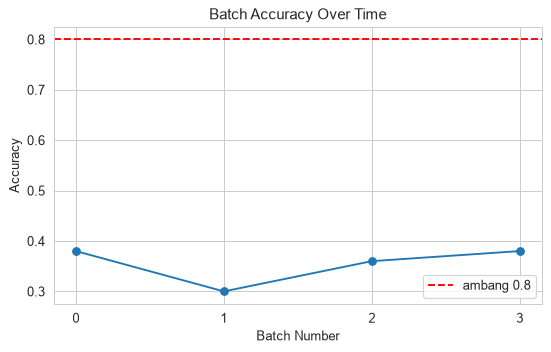

In [11]:
# Latih SGDClassifier inkremental pada data awal
clf = SGDClassifier(loss='log_loss', random_state=2024, warm_start=True)
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))
print('Akurasi pada data training awal:', round(clf.score(X_train, y_train), 3))

# Monitor setiap batch yang datang
batch_scores = []
for xb, yb in zip(stream_batches, stream_labels):
    yf = clf.predict(xb)
    batch_scores.append(np.mean(yf == yb))
print('Akurasi per batch:', np.round(batch_scores, 3))

# Picu retraining bila akurasi turun di bawah ambang (mis. < 0.8)
retrained = False
if min(batch_scores) < 0.8:
    clf.partial_fit(X_pub, y_pub)
    retrained = True
print('Retraining dipicu:', retrained)

# Plot akurasi per batch
plt.figure(figsize=(7, 4))
plt.plot(batch_scores, marker='o')
plt.axhline(0.8, color='red', ls='--', label='ambang 0.8')
plt.title('Batch Accuracy Over Time')
plt.xlabel('Batch Number')
plt.ylabel('Accuracy')
plt.xticks(range(len(batch_scores)))
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**


- Model SGD mencapai akurasi **0.892** pada data training awal, tetapi pada keempat *batch* stream akurasinya hanya **0.38, 0.30, 0.36, 0.38**, lebih buruk dari tebakan acak (0.5). Penyebabnya: data stream dibuat dengan `random_state=2025`, yaitu **proses pembangkit yang berbeda total** (pusat klaster dan hubungan fitur–label berbeda). Ini *concept drift* yang ekstrem: aturan yang dipelajari model hampir berlawanan dengan aturan di data baru.
- Semua titik berada jauh di bawah garis ambang 0.8 (garis merah putus-putus), sehingga kondisi `min(batch_scores) < 0.8` terpenuhi dan **retraining dipicu** (`partial_fit` pada seluruh `X_pub`).
- Catatan: kode buku hanya memperbarui model, tetapi tidak mengukur ulang kinerjanya setelah pembaruan. Sel berikutnya melengkapinya.

Tambahan: (1) mendeteksi *drift* **tanpa label** dengan uji KS dan PSI per fitur, dan (2) mengevaluasi apakah pembaruan `partial_fit` benar-benar memulihkan kinerja. Agar evaluasi jujur, kita ulangi skenario secara *prequential* (*test-then-train*): setiap batch **dievaluasi dulu**, baru dipakai untuk memperbarui model, sehingga akurasi selalu diukur pada data yang belum pernah dilihat.

,KS_stat (stream),KS_p (stream),PSI (stream)
x0,0.068,0.506,0.070
x1,0.064,0.584,0.113
x2,0.141,0.006,0.332
x3,0.274,0.000,0.575
x4,0.151,0.003,0.313
x5,0.120,0.031,0.230
x6,0.205,0.000,0.389
x7,0.092,0.169,0.106
x8,0.143,0.005,0.342
x9,0.064,0.584,0.056


Jumlah fitur dengan KS p < 0.05 : 6
Jumlah fitur dengan PSI > 0.25  : 5


,model statis,prequential (update per batch)
batch 0,0.38,0.38
batch 1,0.30,0.78
batch 2,0.36,0.78
batch 3,0.38,0.80


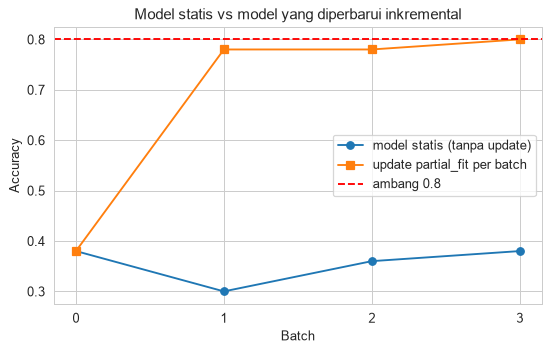

In [12]:
from scipy.stats import ks_2samp

def psi(expected, actual, bins=10):
    # Population Stability Index dengan bin dari kuantil data referensi
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

drift = pd.DataFrame({
    'KS_stat (stream)': [ks_2samp(X_train[:, j], X_pub[:, j]).statistic for j in range(10)],
    'KS_p (stream)':    [ks_2samp(X_train[:, j], X_pub[:, j]).pvalue for j in range(10)],
    'PSI (stream)':     [psi(X_train[:, j], X_pub[:, j]) for j in range(10)],
}, index=[f'x{j}' for j in range(10)])
display(drift.round(3))
print('Jumlah fitur dengan KS p < 0.05 :', int((drift['KS_p (stream)'] < 0.05).sum()))
print('Jumlah fitur dengan PSI > 0.25  :', int((drift['PSI (stream)'] > 0.25).sum()))

# Prequential: evaluasi dulu, lalu update dengan batch tsb.
clf_seq = SGDClassifier(loss='log_loss', random_state=2024)
clf_seq.partial_fit(X_train, y_train, classes=np.unique(y_train))
static = SGDClassifier(loss='log_loss', random_state=2024).partial_fit(X_train, y_train, classes=np.unique(y_train))
preq, stat = [], []
for xb, yb in zip(stream_batches, stream_labels):
    preq.append(clf_seq.score(xb, yb))
    stat.append(static.score(xb, yb))
    clf_seq.partial_fit(xb, yb)          # update SETELAH evaluasi
display(pd.DataFrame({'model statis': stat, 'prequential (update per batch)': preq},
                     index=[f'batch {i}' for i in range(4)]).round(3))

plt.figure(figsize=(7, 4))
plt.plot(stat, marker='o', label='model statis (tanpa update)')
plt.plot(preq, marker='s', label='update partial_fit per batch')
plt.axhline(0.8, color='red', ls='--', label='ambang 0.8')
plt.xticks(range(4)); plt.xlabel('Batch'); plt.ylabel('Accuracy')
plt.title('Model statis vs model yang diperbarui inkremental')
plt.legend(); plt.show()

**Interpretasi:**


- **Deteksi drift tanpa label:** uji KS menemukan **6 dari 10** fitur dengan $p < 0.05$, dan **5 fitur** memiliki PSI > 0.25 (drift signifikan). Yang terbesar adalah `x3` (KS = 0.274, PSI = 0.575) dan `x6` (KS = 0.205, PSI = 0.389). Fitur `x0`, `x1`, `x9` tidak berubah signifikan (p ≈ 0.5–0.58, PSI < 0.12). Artinya drift sudah dapat terdeteksi dari distribusi input saja, sebelum label tersedia.
- **Model statis vs prequential:** model yang tidak diperbarui tetap di kisaran **0.30–0.38** di semua *batch*. Model yang di-*update* dengan `partial_fit` setelah setiap *batch* tetap buruk di batch 0 (**0.38**, karena belum pernah melihat data baru), lalu naik ke **0.78, 0.78, 0.80** pada batch 1–3. Karena setiap batch dievaluasi **sebelum** dipakai untuk update, angka ini merupakan estimasi jujur. Pembelajaran inkremental memulihkan kinerja dengan cepat, walaupun bobot lama dari data training awal masih sedikit "menarik" model sehingga akurasi belum melampaui ~0.8.

## 13.5 Mengelola Siklus Hidup Model

**Teori:**

**Manajemen siklus hidup model** (*model lifecycle management*) memastikan model tetap **andal, dapat direproduksi, dapat diaudit, dan dapat dikembalikan** (*rollback*). Tahapan umumnya: *develop → validate → register → deploy → monitor → retire*.

**Komponen penting:**

1. **Versioning artefak** — setiap model diberi versi unik, idealnya *semantic versioning* `MAJOR.MINOR.PATCH` (mis. `v1.0` → `v1.1` saat retrain dengan data baru, `v2.0` saat fitur input berubah sehingga kontrak API berubah). Nama berkas berversi (`rf_v1.0.joblib`) memungkinkan *rollback* cepat.
2. **Metadata / model card** — versi Python & pustaka, hyperparameter, daftar fitur, tanggal training, hash data training, metrik validasi. Tanpa ini, model lama tidak bisa dijelaskan atau dipercaya.
3. **Integritas** — *checksum* (mis. SHA-256) artefak: $h = \text{SHA256}(\text{bytes})$. Saat memuat di produksi, hash dihitung ulang; bila berbeda, berkas rusak atau dimodifikasi.
4. **Snapshot validasi** — dokumentasi scikit-learn menyarankan menyimpan *bukan hanya model*, tetapi juga kode training, versi pustaka, dan **sekumpulan kecil data validasi beserta prediksinya**. Setelah *upgrade* pustaka atau migrasi server, model dimuat ulang dan prediksinya dibandingkan dengan snapshot — bila sama, migrasi aman.
5. **Model registry** — alat seperti MLflow, Weights & Biases, atau DVC menyimpan artefak + metadata + status (*staging*, *production*, *archived*) secara terpusat.

**Pitfall:** versi pustaka ditulis manual (bisa salah — lebih baik dibaca otomatis dari `sklearn.__version__`); data validasi bocor dari data training sehingga metrik terlalu optimistis; tidak menyimpan *random seed* dan daftar fitur.

Kode buku: melatih random forest yang akan diberi versi.

In [13]:
# Melatih model dan mensimulasikan lingkungan versioning
X, y = make_classification(n_samples=800, n_features=20, random_state=2024)
clf = RandomForestClassifier(n_estimators=50, random_state=2024)
clf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",2024
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

Kode buku (disesuaikan): menyimpan artefak berversi, metadata lingkungan, dan snapshot akurasi validasi. Perubahan: versi scikit-learn dibaca otomatis (buku menulis `"1.3.2"` secara manual), semua berkas ditulis ke `ART_DIR`.

In [14]:
# Catatan: Xv di sini diambil dari X yang SAMA dengan yang dipakai melatih clf (sesuai buku)
Xv, _, yv, _ = train_test_split(X, y, test_size=0.8, random_state=2024)

# Simpan artefak model dengan nama berversi
version = 'v1.0'
dump(clf, ART_DIR / f'rf_{version}.joblib')

# Simpan metadata lingkungan training
meta = {'version': version, 'sklearn': sklearn.__version__, 'numpy': str(np.__version__)}
with open(ART_DIR / f'rf_{version}_metadata.json', 'w') as f:
    json.dump(meta, f)

# Snapshot kinerja pada set validasi
yv_pred = clf.predict(Xv)
val_acc = accuracy_score(yv, yv_pred)
with open(ART_DIR / f'rf_{version}_val.txt', 'w') as f:
    f.write(f'{val_acc:.4f}')

print('Metadata          :', meta)
print('Ukuran set "validasi":', len(Xv), '| akurasi:', f'{val_acc:.4f}')
print('Berkas di ART_DIR :', sorted(p.name for p in ART_DIR.glob('rf_v1.0*')))

Metadata          : {'version': 'v1.0', 'sklearn': '1.9.1', 'numpy': '2.5.4'}
Ukuran set "validasi": 160 | akurasi: 1.0000
Berkas di ART_DIR : ['rf_v1.0.joblib', 'rf_v1.0_metadata.json', 'rf_v1.0_val.txt']


**Interpretasi:**


- Tiga berkas tercipta: artefak `rf_v1.0.joblib`, metadata `rf_v1.0_metadata.json` (versi scikit-learn **1.9.1** dan NumPy **2.5.4**, kini dibaca otomatis, bukan ditulis manual `"1.3.2"` seperti di buku), dan snapshot akurasi `rf_v1.0_val.txt`.
- Akurasi "validasi" tercatat **1.0000** pada 160 sampel. Angka ini **menyesatkan**: `Xv` diambil dengan `train_test_split` dari `X` yang **sama** dengan yang dipakai melatih `clf`, sehingga random forest hanya "mengingat" data trainingnya. Snapshot seperti ini tetap berguna sebagai uji regresi (model yang dimuat ulang harus menghasilkan prediksi yang sama), tetapi **tidak boleh** dibaca sebagai estimasi kinerja. Sel berikutnya memperbaikinya dengan *hold-out* yang benar.

Tambahan: versi yang lebih ketat — validasi pada data *hold-out* yang benar-benar tidak dipakai training, metadata lengkap (hyperparameter, hash SHA-256, snapshot prediksi), lalu simulasi "lingkungan produksi" yang memverifikasi artefak sebelum dipakai.

In [15]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

X_tr, X_ho, y_tr, y_ho = train_test_split(X, y, test_size=0.2, random_state=2024, stratify=y)
clf_v11 = RandomForestClassifier(n_estimators=50, random_state=2024).fit(X_tr, y_tr)

version = 'v1.1'
art = ART_DIR / f'rf_{version}.joblib'
dump(clf_v11, art)
snapshot_X = X_ho[:20]
card = {
    'version': version,
    'created_at': time.strftime('%Y-%m-%dT%H:%M:%S'),
    'python': platform.python_version(),
    'sklearn': sklearn.__version__, 'numpy': np.__version__, 'joblib': joblib.__version__,
    'estimator': type(clf_v11).__name__,
    'params': {k: v for k, v in clf_v11.get_params().items() if k in ('n_estimators', 'max_depth', 'random_state')},
    'n_features_in': int(clf_v11.n_features_in_),
    'train_size': len(X_tr), 'holdout_size': len(X_ho),
    'holdout_accuracy': round(float(clf_v11.score(X_ho, y_ho)), 4),
    'artifact_sha256': sha256(art),
    'snapshot_predictions': clf_v11.predict_proba(snapshot_X)[:, 1].round(6).tolist(),
}
(ART_DIR / f'rf_{version}_card.json').write_text(json.dumps(card, indent=2))
np.save(ART_DIR / f'rf_{version}_snapshot_X.npy', snapshot_X)
print(json.dumps({k: v for k, v in card.items() if k != 'snapshot_predictions'}, indent=2))

# ---- "Lingkungan produksi": verifikasi sebelum memakai model ----
def load_verified(version):
    card = json.loads((ART_DIR / f'rf_{version}_card.json').read_text())
    art = ART_DIR / f'rf_{version}.joblib'
    assert sha256(art) == card['artifact_sha256'], 'Checksum tidak cocok!'
    if card['sklearn'] != sklearn.__version__:
        print('PERINGATAN: versi sklearn berbeda dari saat training')
    model = load(art)
    Xs = np.load(ART_DIR / f'rf_{version}_snapshot_X.npy')
    assert np.allclose(model.predict_proba(Xs)[:, 1], card['snapshot_predictions'], atol=1e-6), 'Snapshot berbeda!'
    return model

prod_model = load_verified('v1.1')
print('\nArtefak v1.1 lolos verifikasi checksum + snapshot.')

# Simulasi artefak yang rusak/dimodifikasi
with open(ART_DIR / 'rf_v1.1.joblib', 'ab') as f:
    f.write(b'tampered')
try:
    load_verified('v1.1')
except AssertionError as e:
    print('Artefak dimodifikasi terdeteksi ->', e)

{
  "version": "v1.1",
  "created_at": "2026-10-24T23:27:12",
  "python": "3.12.15",
  "sklearn": "1.9.1",
  "numpy": "2.5.4",
  "joblib": "1.6.0",
  "estimator": "RandomForestClassifier",
  "params": {
    "max_depth": null,
    "n_estimators": 50,
    "random_state": 2024
  },
  "n_features_in": 20,
  "train_size": 640,
  "holdout_size": 160,
  "holdout_accuracy": 0.925,
  "artifact_sha256": "b6e5d2110df7f03bd5b17305f7d20c5fffab897fc9203d9eaf459ccf5a427f88"
}

Artefak v1.1 lolos verifikasi checksum + snapshot.
Artefak dimodifikasi terdeteksi -> Checksum tidak cocok!


**Interpretasi:**


- Dengan *hold-out* yang benar (640 sampel training, 160 sampel uji yang tidak pernah dilihat), akurasi **0.925**. Angka inilah estimasi kinerja yang jujur, dibandingkan 1.0 pada snapshot buku.
- *Model card* mencatat semua yang dibutuhkan untuk audit dan reproduksi: versi Python/scikit-learn/NumPy/joblib, hyperparameter, jumlah fitur (20), ukuran data, metrik, dan hash SHA-256 artefak.
- Fungsi `load_verified` berhasil memverifikasi artefak v1.1 (checksum cocok dan `predict_proba` pada 20 baris snapshot sama hingga $10^{-6}$). Setelah 8 byte ditambahkan ke berkas, verifikasi gagal dengan *"Checksum tidak cocok!"*: berkas yang rusak atau dimodifikasi terdeteksi **sebelum** di-*unpickle*. Urutan ini penting, karena memuat pickle yang dimodifikasi bisa mengeksekusi kode berbahaya.

## 13.6 Menyiapkan Deployment Pipeline

**Teori:**

**Otomatisasi** adalah kunci deployment yang andal: setiap perubahan kode atau data memicu rangkaian langkah yang sama — *train → serialize → validate → (approve) → deploy*. Dua konsep berperan:

1. **`sklearn.pipeline.Pipeline` sebagai satu artefak.** Dengan menggabungkan preprocessing (mis. `StandardScaler`) dan model dalam satu objek, statistik preprocessing ($\mu_j, \sigma_j$ hasil `fit` pada data training) ikut tersimpan. Di produksi cukup memanggil `pipe.predict(X_raw)`, sehingga transformasi $z_{ij} = (x_{ij}-\mu_j)/\sigma_j$ dijamin identik dengan saat training — menghindari *training–serving skew*.

2. **Quality gate (gerbang kualitas) di CI/CD.** Sebelum model dipromosikan, skrip CI memuat artefak dan mengevaluasinya pada **set validasi/canary** yang representatif. Model hanya di-*deploy* bila memenuhi kriteria, misalnya
$$\text{acc}_{\text{val}} > \tau \quad\text{dan}\quad \text{acc}_{\text{val}}^{\text{challenger}} \ge \text{acc}_{\text{val}}^{\text{champion}} - \delta,$$
yaitu model baru (*challenger*) tidak boleh lebih buruk dari model produksi (*champion*) lebih dari toleransi $\delta$. Ini mencegah **regresi senyap** (*silent regression*).

**Strategi rilis** setelah lolos gate: *blue–green* (dua lingkungan, trafik dialihkan sekaligus), *canary release* (sebagian kecil trafik dulu, mis. 5%), dan *shadow deployment* (model baru menerima trafik nyata tetapi prediksinya hanya dicatat, tidak dipakai).

**Pitfall:** set validasi yang tidak representatif (atau acak tanpa makna) membuat gate tidak berguna; ambang yang ditetapkan tanpa melihat *baseline*; serta lupa mengunci seed sehingga hasil CI tidak deterministik.

Kode buku: membuat `Pipeline` (scaler + logistic regression) dan melatihnya.

In [16]:
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ('scale', StandardScaler()),
    ('clf', LogisticRegression())
])
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Kode buku: mengekspor pipeline, memuatnya kembali di "lingkungan deployment", memvalidasi pada set uji, lalu mengambil keputusan deploy berdasarkan ambang 0.8.

In [17]:
# Ekspor seluruh pipeline
dump(pipe, ART_DIR / 'pipeline.joblib')

# Muat pipeline di lingkungan deployment
prod_pipe = load(ART_DIR / 'pipeline.joblib')

# Simulasi CI: validasi akurasi pada set uji (sesuai buku: fitur & label ACAK)
np.random.seed(2024)
Xt, yt = np.random.rand(100, 10), np.random.randint(0, 2, 100)
acc = accuracy_score(yt, prod_pipe.predict(Xt))
print('Validation accuracy:', acc)

# Deploy hanya bila akurasi > ambang (mis. > 0.8)
if acc > 0.8:
    print('Auto-deploy allowed')
else:
    print('Halt deployment and review')

Validation accuracy: 0.52
Halt deployment and review


**Interpretasi:**


- Pipeline berhasil diekspor dan dimuat kembali sebagai satu artefak (scaler + model). Namun akurasi validasinya hanya **0.52**, sehingga keputusan gate adalah **"Halt deployment and review"**.
- Hasil ini **bukan** karena modelnya buruk. Penyebabnya adalah set validasi di kode buku: fitur `np.random.rand` dan label `np.random.randint` dibangkitkan **acak dan saling independen**, sehingga tidak ada model apa pun yang dapat melampaui ~50%. Pelajarannya: *quality gate* hanya sebaik data validasinya. Set validasi harus representatif terhadap data produksi.

Tambahan: *quality gate* yang lebih realistis. Data validasi diambil dari proses yang sama dengan data training (*hold-out*), dibandingkan dengan *baseline* `DummyClassifier`, dan sebuah model *challenger* dibandingkan dengan *champion*. Logika gate ditulis sebagai fungsi agar dapat dipanggil dari skrip CI.

In [18]:
from sklearn.dummy import DummyClassifier

X_all, y_all = make_classification(n_samples=1500, n_features=10, random_state=2024)
X_tr, X_val, y_tr, y_val = train_test_split(X_all, y_all, test_size=0.3, random_state=2024, stratify=y_all)

def quality_gate(model_path, X_val, y_val, threshold=0.8, champion_acc=None, tolerance=0.01):
    model = load(model_path)
    acc = accuracy_score(y_val, model.predict(X_val))
    checks = {f'acc > {threshold}': acc > threshold}
    if champion_acc is not None:
        checks[f'acc >= champion - {tolerance}'] = acc >= champion_acc - tolerance
    return acc, checks, all(checks.values())

baseline = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
print('Baseline (kelas mayoritas) acc:', round(baseline.score(X_val, y_val), 3))

# Champion: pipeline logistic regression yang sedang di produksi
champion = Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression())]).fit(X_tr, y_tr)
dump(champion, ART_DIR / 'champion.joblib')
champ_acc, checks, ok = quality_gate(ART_DIR / 'champion.joblib', X_val, y_val)
print(f'\nChampion  acc={champ_acc:.3f} checks={checks} -> {"DEPLOY" if ok else "HALT"}')

# Dua challenger: random forest, dan SGD (hinge) dengan regularisasi sangat kuat (seperti Exercise 2)
candidates = {
    'challenger_rf': RandomForestClassifier(n_estimators=100, random_state=2024),
    'challenger_sgd_a1': SGDClassifier(loss='hinge', alpha=1.0, random_state=2024),
}
for name, model in candidates.items():
    model.fit(X_tr, y_tr)
    dump(model, ART_DIR / f'{name}.joblib')
    acc, checks, ok = quality_gate(ART_DIR / f'{name}.joblib', X_val, y_val, champion_acc=champ_acc)
    print(f'{name:<18} acc={acc:.3f} checks={checks} -> {"PROMOTE" if ok else "REJECT"}')

Baseline (kelas mayoritas) acc: 0.502

Champion  acc=0.922 checks={'acc > 0.8': True} -> DEPLOY


challenger_rf      acc=0.973 checks={'acc > 0.8': True, 'acc >= champion - 0.01': True} -> PROMOTE
challenger_sgd_a1  acc=0.904 checks={'acc > 0.8': True, 'acc >= champion - 0.01': False} -> REJECT


**Interpretasi:**


- Dengan data validasi yang benar (450 sampel *hold-out* dari proses yang sama), *baseline* kelas mayoritas mencapai **0.502**, dan pipeline logistic regression (*champion*) mencapai **0.922**, sehingga lolos ambang 0.8 dan berstatus **DEPLOY**.
- *Challenger* random forest mencapai **0.973**, yaitu lolos ambang dan lebih baik dari champion, sehingga **PROMOTE**.
- *Challenger* SGD (hinge, `alpha=1.0`) mencapai **0.904**. Model ini **lolos** ambang absolut 0.8, tetapi **gagal** pada pemeriksaan relatif terhadap champion ($0.904 < 0.922 - 0.01$), sehingga **REJECT**. Ini menunjukkan mengapa ambang absolut saja tidak cukup: tanpa perbandingan champion–challenger, model yang lebih buruk dari model produksi akan lolos tanpa terdeteksi (*silent regression*).

### Menjalankan gate di CI (tidak dijalankan di notebook)

Logika `quality_gate` biasanya ditempatkan dalam skrip/test yang dijalankan otomatis oleh sistem CI. Contoh test `pytest` (`tests/test_model_gate.py`):

```python
def test_model_meets_threshold():
    acc, checks, ok = quality_gate("artifacts/challenger.joblib", X_val, y_val,
                                   threshold=0.8, champion_acc=load_champion_acc())
    assert ok, f"Quality gate gagal: acc={acc:.3f}, checks={checks}"
```

Contoh *workflow* GitHub Actions (`.github/workflows/model.yml`): setiap *push* melatih ulang model, menjalankan gate, dan hanya membangun/men-*push* image Docker bila semua langkah sukses.

```yaml
name: train-validate-deploy
on: [push]
jobs:
  ml:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: {python-version: "3.12"}
      - run: pip install -r requirements.txt
      - run: python train.py            # menghasilkan artifacts/challenger.joblib + model card
      - run: pytest tests/test_model_gate.py   # quality gate; gagal => pipeline berhenti
      - run: docker build -t registry.example.com/model-api:${{ github.sha }} .
      - run: docker push registry.example.com/model-api:${{ github.sha }}
```

Karena setiap langkah harus sukses agar langkah berikutnya berjalan, model yang tidak lolos gate **tidak akan pernah** sampai ke produksi.

## Latihan

Bagian ini mereproduksi notebook *Exercise Solutions* resmi: tiga latihan yang merangkum alur deployment — menyimpan & memuat pipeline, memantau akurasi pada data streaming, dan gate validasi otomatis.

### Exercise 1: Menyimpan dan Memuat Ulang Pipeline untuk Deployment

**Teori:** Pipeline membundel preprocessing + inferensi menjadi satu artefak, sehingga di lingkungan produksi cukup `load()` lalu `predict()` pada data mentah. Uji minimal setelah memuat: prediksi pipeline yang dimuat sama dengan pipeline asli.

In [19]:
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])
pipe.fit(X, y)

# Simpan dan muat ulang pipeline
dump(pipe, ART_DIR / 'model_pipeline.joblib')
loaded_pipe = load(ART_DIR / 'model_pipeline.joblib')

# Prediksi baru
print('Prediksi 5 sampel pertama :', loaded_pipe.predict(X[:5]))
print('Label asli                :', y[:5])
print('Identik dengan pipe asli  :', np.array_equal(pipe.predict(X), loaded_pipe.predict(X)))
print('Mean scaler tersimpan (3 fitur pertama):', loaded_pipe.named_steps['scaler'].mean_[:3].round(4))

Prediksi 5 sampel pertama : [1 1 1 0 0]
Label asli                : [1 1 0 0 0]
Identik dengan pipe asli  : True
Mean scaler tersimpan (3 fitur pertama): [-0.0061 -0.0236 -0.0217]


**Interpretasi:**


- Pipeline (`StandardScaler` + `LogisticRegression`) yang dimuat ulang memprediksi `[1 1 1 0 0]` untuk 5 sampel pertama, sedangkan label aslinya `[1 1 0 0 0]` (sampel ke-3 salah). Prediksinya **identik** dengan pipeline asli di seluruh 500 baris.
- Rata-rata yang dipelajari scaler (mis. −0.0061, −0.0236, −0.0217 untuk tiga fitur pertama) ikut tersimpan dalam artefak. Di produksi, data mentah akan distandardisasi dengan statistik **training** yang sama, sehingga *training–serving skew* dapat dihindari.

### Exercise 2: Memantau Akurasi Model dari Waktu ke Waktu

**Teori:** Solusi resmi sengaja membuat model **lebih buruk** — `loss="hinge"` (SVM linear) dengan regularisasi sangat kuat `alpha=1.0` — untuk melihat bagaimana monitoring memperlihatkan kinerja rendah. Dengan penalti L2 $\tfrac{\alpha}{2}\lVert w\rVert^2$ yang besar, bobot ditekan mendekati nol sehingga model mengalami *underfitting*. Data stream dan batch sama dengan resep 13.4.

Akurasi training awal : 0.902
Akurasi per batch     : [0.38 0.22 0.3  0.28]
Norma bobot ||w||     : 0.5604


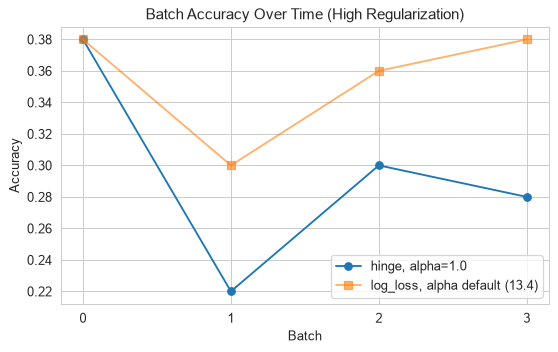

In [20]:
# Data sama dengan 13.4 (dibuat ulang agar sel ini mandiri)
X_train, y_train = make_classification(n_samples=500, n_features=10, random_state=2024)
X_pub, y_pub = make_classification(n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub, 4)
stream_labels = np.array_split(y_pub, 4)

# Ubah hyperparameter SGDClassifier agar model kurang akurat
clf = SGDClassifier(loss='hinge', alpha=1.0, random_state=2024)  # SVM loss + regularisasi kuat
clf.partial_fit(X_train, y_train, classes=np.unique(y_train))
batch_scores_ex = []
for Xb, yb in zip(stream_batches, stream_labels):
    acc = np.mean(clf.predict(Xb) == yb)
    batch_scores_ex.append(acc)
print('Akurasi training awal :', round(clf.score(X_train, y_train), 3))
print('Akurasi per batch     :', np.round(batch_scores_ex, 3))
print('Norma bobot ||w||     :', round(float(np.linalg.norm(clf.coef_)), 4))

# Plot akurasi per batch (dibandingkan dengan model 13.4)
plt.figure(figsize=(7, 4))
plt.plot(batch_scores_ex, marker='o', label='hinge, alpha=1.0')
plt.plot(batch_scores, marker='s', alpha=0.6, label='log_loss, alpha default (13.4)')
plt.xlabel('Batch')
plt.ylabel('Accuracy')
plt.xticks(range(4))
plt.title('Batch Accuracy Over Time (High Regularization)')
plt.legend()
plt.grid(True)
plt.show()

**Interpretasi:**


- Dengan `loss='hinge'` dan `alpha=1.0`, norma bobot hanya **0.56** karena regularisasi kuat menekan $w$ ke arah nol. Akurasi training awal tetap **0.902**, karena data ini mudah dipisahkan oleh beberapa fitur informatif sehingga arah $w$ masih benar walaupun besarnya kecil.
- Pada data stream, akurasinya **0.38, 0.22, 0.30, 0.28**, sedikit lebih rendah daripada model 13.4 (0.38, 0.30, 0.36, 0.38) yang ikut ditampilkan pada grafik. Kedua model sama-sama jatuh jauh di bawah 0.5 karena *concept drift* yang sama. Hiperparameter yang lebih buruk memperparah penurunan, tetapi penyebab utamanya tetap pergeseran data. Grafik ini menunjukkan peran monitoring: tanpa label stream, kita tidak akan tahu model sedang gagal.

### Exercise 3: Mengotomatiskan Pemeriksaan Deployment dengan Ambang Validasi

**Teori:** Simulasi langkah CI/CD: model dilatih, diekspor, dimuat kembali, diuji pada data uji, dan hanya disetujui bila akurasinya melewati ambang 0.8. Perhatikan bahwa data uji solusi resmi dibuat dengan `random_state=2025`, yaitu dari **proses pembangkit yang berbeda** dari data training (`random_state=2024`) — ini relevan untuk membaca hasilnya.

In [21]:
# Latih dan ekspor model
X, y = make_classification(n_samples=300, n_features=10, random_state=2024)
model = LogisticRegression()
model.fit(X, y)
dump(model, ART_DIR / 'model_ci.joblib')

# Muat dan validasi dengan data uji
Xt, yt = make_classification(n_samples=100, n_features=10, random_state=2025)
model_prod = load(ART_DIR / 'model_ci.joblib')
pred = model_prod.predict(Xt)
acc = accuracy_score(yt, pred)
print(f'Test Accuracy: {acc:.3f}')

# Setujui deployment secara kondisional
if acc > 0.8:
    print('Deployment approved')
else:
    print('Deployment rejected')

# Pembanding: hold-out dari proses pembangkit yang SAMA.
# (make_classification dengan n_samples berbeda menghasilkan proses berbeda, jadi
#  kita buat 400 sampel sekaligus: 300 untuk training, 100 untuk uji.)
X_big, y_big = make_classification(n_samples=400, n_features=10, random_state=2024)
model_same = LogisticRegression().fit(X_big[:300], y_big[:300])
acc_same = accuracy_score(y_big[300:], model_same.predict(X_big[300:]))
print(f'Akurasi pada hold-out dari distribusi yang sama: {acc_same:.3f}')
print('Deployment approved' if acc_same > 0.8 else 'Deployment rejected', '(skenario pembanding)')

Test Accuracy: 0.110
Deployment rejected
Akurasi pada hold-out dari distribusi yang sama: 0.850
Deployment approved (skenario pembanding)


**Interpretasi:**


- Model yang dilatih pada data `random_state=2024` hanya mencapai akurasi **0.110** pada data uji `random_state=2025`, sehingga **Deployment rejected**. Akurasi 0.11 jauh di bawah tebakan acak, artinya prediksi model hampir **terbalik** terhadap label sebenarnya. Data uji berasal dari proses pembangkit lain, sehingga hubungan fitur–label di sana kebetulan hampir berlawanan.
- Sebagai pembanding, model yang sama dilatih dan diuji pada *hold-out* dari proses yang **sama** (300/100 dari 400 sampel `random_state=2024`) mencapai **0.850**, sehingga **Deployment approved**. Gate bekerja sebagaimana mestinya dalam kedua kasus: ia menahan model yang tidak cocok dengan data uji dan meloloskan model yang cocok. Kesimpulan yang diambil gate tetap bergantung pada seberapa representatif data ujinya.

### Membersihkan artefak sementara

In [22]:
print('Berkas yang dibuat selama notebook:', len(list(ART_DIR.iterdir())))
shutil.rmtree(ART_DIR, ignore_errors=True)
print('Direktori sementara dihapus:', not ART_DIR.exists())

Berkas yang dibuat selama notebook: 18
Direktori sementara dihapus: True


## Ringkasan Chapter 13


1. **Deployment = memisahkan training dan inference.** Model dilatih sekali, dipersistensikan sebagai artefak (`joblib.dump`), lalu dimuat di lingkungan produksi. Selalu verifikasi *round-trip*: model hasil muat ulang memberi prediksi dan koefisien yang identik dengan model asli.
2. **Serving lewat REST API.** Model dibungkus dalam Flask atau FastAPI, dimuat sekali saat aplikasi start, menyediakan `/health` dan `/predict`, serta memvalidasi skema input (HTTP 422 untuk input salah). Aplikasi dikemas dalam Docker dengan versi pustaka yang di-*pin* agar lingkungan training dan serving identik.
3. **Serialisasi.** `pickle` dan `joblib` setara untuk model kecil (`joblib` unggul pada array besar dan mendukung kompresi, ~4× lebih kecil di sini). Keduanya **tidak aman** untuk berkas tak tepercaya. `skops` menawarkan format aman dengan daftar tipe tepercaya, dan ONNX memungkinkan inferensi tanpa Python dengan selisih numerik ~$10^{-7}$ (float32).
4. **Scaling.** `n_jobs=-1` mempercepat training random forest (dibatasi hukum Amdahl). Untuk inferensi, *batch serving* jauh lebih efisien daripada prediksi per baris (di sini ratusan kali lipat) karena overhead tetap per panggilan mendominasi. Untuk skala klaster, Dask/Ray dapat menjadi backend joblib.
5. **Monitoring & CT.** Model pasti menurun akibat *data/concept drift*. Kinerja per *batch* (bila label tersedia) serta uji KS/PSI pada distribusi fitur (tanpa label) mendeteksi drift. Pada contoh ini akurasi jatuh dari 0.89 ke ~0.3–0.38, dan pembaruan inkremental `partial_fit` memulihkannya ke ~0.8 dalam evaluasi *prequential* yang jujur.
6. **Lifecycle.** Beri versi pada artefak dan simpan *model card* (versi pustaka yang dibaca otomatis, hyperparameter, metrik hold-out, hash SHA-256, snapshot prediksi). Verifikasi checksum **sebelum** memuat. Hati-hati dengan metrik validasi yang bocor dari data training (akurasi 1.0 di buku vs 0.925 pada hold-out yang benar).
7. **Deployment pipeline.** Simpan seluruh `Pipeline` (preprocessing + model) sebagai satu artefak untuk menghindari *training–serving skew*. Jalankan *quality gate* otomatis di CI: ambang absolut **dan** perbandingan champion–challenger. Gate hanya sebaik data validasinya: data acak di contoh buku menghasilkan 0.52 untuk model yang sebenarnya baik (0.92 pada data yang representatif).